# Image Noise Removal — Spatial and Frequency Domain Filters



In [1]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
import os



# Load Image
Place your grayscale image inside the `images/` folder.


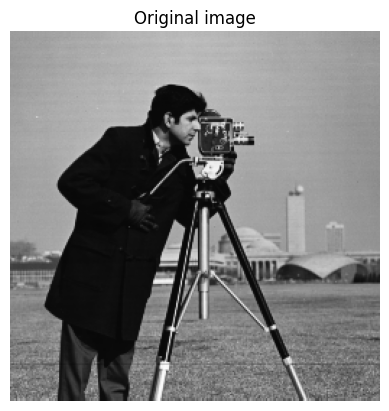

In [2]:
from pathlib import Path
IMAGE_PATH = Path("/content/images/camera_man.png")

def load_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) if Path(path).exists() else None
    if img is None:
        print("Image unavailable; using the skimage camera sample instead.")
        from skimage.data import camera
        img = camera()
    return img

original = load_image(IMAGE_PATH)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original image")
plt.axis("off")
plt.show()


# Add Noise
We will add:
- Gaussian Noise
- Salt & Pepper Noise


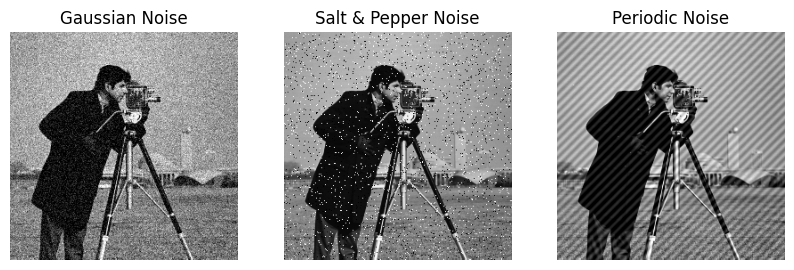

In [3]:

rng = np.random.default_rng(42)  # reproducible experiments

def add_gaussian_noise(image, mean=0, std=25):

    noise = rng.normal(mean, std, image.shape)

    noisy = image.astype(np.float64) + noise

    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_salt_and_pepper_noise(image, density=0.05):

    noisy = image.copy()

    total_pixels = image.size
    num_corrupted = int(density * total_pixels)

    selected = rng.choice(total_pixels, size=min(num_corrupted, total_pixels), replace=False)
    salt = selected[:len(selected)//2]
    pepper = selected[len(selected)//2:]
    noisy.flat[salt] = 255
    noisy.flat[pepper] = 0

    return noisy


def add_periodic_noise(img, amplitude=30, freq_x=25, freq_y=25):

    h, w = img.shape

    noisy = img.astype(np.float32).copy()

    i, j = np.indices((h, w))
    noise = amplitude * np.sin(2 * np.pi * (freq_x * i / h + freq_y * j / w))
    noisy += noise

    return np.clip(noisy, 0, 255).astype(np.uint8)


gaussian_noisy = add_gaussian_noise(original)

sp_noisy = add_salt_and_pepper_noise(original)

periodic_noisy = add_periodic_noise(original)

fig, axes = plt.subplots(1,3, figsize=(10,5))

axes[0].imshow(gaussian_noisy, cmap='gray')
axes[0].set_title("Gaussian Noise")
axes[0].axis('off')

axes[1].imshow(sp_noisy, cmap='gray')
axes[1].set_title("Salt & Pepper Noise")
axes[1].axis('off')

axes[2].imshow(periodic_noisy, cmap='gray')
axes[2].set_title("Periodic Noise")
axes[2].axis('off')

plt.show()



# Helper Function — Padding


In [4]:
def pad_image(image, pad):
    """Reflect padding avoids artificial dark borders from zero padding."""
    return np.pad(image.astype(np.float64), pad, mode="reflect")


# Spatial Domain Filters
Implemented manually:
- Mean Filter
- Weighted Mean Filter
- Gaussian Filter
- Geometric Filter
- Harmonic Filter
- Countra Harmonic Filter
- Median Filter
- Adaptive Median Filter
- Min Filter
- Max Filter
- Alpha Trimmed Filter


In [5]:

def mean_filter(image, kernel_size=3):

    pad = kernel_size // 2

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+kernel_size, j:j+kernel_size]

            output[i,j] = np.sum(region) / (kernel_size * kernel_size)

    return np.clip(output,0,255).astype(np.uint8)


def weighted_mean_filter(image):

    kernel = np.array([
        [1,2,1],
        [2,4,2],
        [1,2,1]
    ], dtype=np.float64)

    kernel = kernel / 16

    pad = 1

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+3, j:j+3]

            output[i,j] = np.sum(region * kernel)

    return np.clip(output,0,255).astype(np.uint8)


def gaussian_kernel(size, sigma):

    kernel = np.zeros((size,size))

    center = size // 2

    for x in range(size):
        for y in range(size):

            dx = x - center
            dy = y - center

            kernel[x,y] = np.exp(-(dx**2 + dy**2)/(2*sigma**2))

    kernel = kernel / kernel.sum()

    return kernel


def gaussian_filter(image, kernel_size=5, sigma=1):

    kernel = gaussian_kernel(kernel_size, sigma)

    pad = kernel_size // 2

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+kernel_size, j:j+kernel_size]

            output[i,j] = np.sum(region * kernel)

    return np.clip(output,0,255).astype(np.uint8)


def geomtric_mean_filter(image, kernel_size=3): #smoothing + lose less details
  pad = kernel_size // 2
  padded = pad_image(image, pad)

  h, w = image.shape

  output = np.zeros((h,w))

  for i in range(h):
    for j in range(w):
      region = padded[i:i+kernel_size, j:j+kernel_size]

      region = region.astype(np.float64)
      value = np.exp(np.mean(np.log(np.maximum(region, 1e-8))))

      output[i,j] = value

  return np.clip(output,0,255).astype(np.uint8)


def harmonic_mean_filter(image, kernel_size=3): # gaussian + salt
  pad = kernel_size // 2
  padded = pad_image(image, pad)

  h, w = image.shape

  output = np.zeros((h,w))

  for i in range(h):
    for j in range(w):
      region = padded[i:i+kernel_size, j:j+kernel_size]

      region = region.astype(np.float32) + 1e-8

      value = (kernel_size**2) / np.sum(1 / (region ))
      output[i,j] = value

  return np.clip(output,0,255).astype(np.uint8)


def countra_harmonic_mean_filter_for_pepper(image, kernel_size=3, Q = 1.5 ): # for pepper noise
  pad = kernel_size // 2
  padded = pad_image(image, pad)

  h,w = image.shape

  output = np.zeros((h,w))

  for i in range(h):
    for j in range(w):
      region = padded[i:i+kernel_size, j:j+kernel_size]

      region = region.astype(np.float64)
      num = np.sum(region ** (Q + 1))
      den = np.sum(region ** Q)

      value = num / den if den > 1e-12 else 0
      output[i,j] = value

  return np.clip(output,0,255).astype(np.uint8)


def countra_harmonic_mean_filter_for_salt(image, kernel_size=3, Q = -1.5 ): # for salt noise
  pad = kernel_size // 2
  padded = pad_image(image, pad)

  h,w = image.shape

  output = np.zeros((h,w))

  for i in range(h):
    for j in range(w):
      region = padded[i:i+kernel_size, j:j+kernel_size]

      region = region.astype(np.float32) + 1e-8

      region = region.astype(np.float64)
      num = np.sum(region ** (Q + 1))
      den = np.sum(region ** Q)

      value = num / den if den > 1e-12 else 0
      output[i,j] = value

  return np.clip(output,0,255).astype(np.uint8)


def median_filter(image, kernel_size=3):

    pad = kernel_size // 2

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+kernel_size, j:j+kernel_size]

            flat = region.flatten()

            flat.sort()

            output[i,j] = flat[len(flat)//2]

    return np.clip(output,0,255).astype(np.uint8)



def adaptive_median_filter(img, max_kernel_size=7):
    """Adaptive median stages A/B with one precomputed reflect-padded image."""
    if max_kernel_size < 3 or max_kernel_size % 2 == 0:
        raise ValueError("max_kernel_size must be odd and >= 3")
    h, w = img.shape
    output = np.empty_like(img)
    max_pad = max_kernel_size // 2
    padded = pad_image(img, max_pad)
    for i in range(h):
        for j in range(w):
            z_xy = float(img[i, j])
            z_med = z_xy
            for size in range(3, max_kernel_size + 1, 2):
                radius = size // 2
                ci, cj = i + max_pad, j + max_pad
                region = padded[ci-radius:ci+radius+1, cj-radius:cj+radius+1]
                z_min, z_max, z_med = float(region.min()), float(region.max()), float(np.median(region))
                if z_min < z_med < z_max:
                    break
            output[i, j] = z_xy if z_min < z_xy < z_max and z_min < z_med < z_max else z_med
    return output


def min_filter(image, kernel_size=3):

    pad = kernel_size // 2

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+kernel_size, j:j+kernel_size]

            output[i,j] = np.min(region)

    return np.clip(output,0,255).astype(np.uint8)


def max_filter(image, kernel_size=3):

    pad = kernel_size // 2

    padded = pad_image(image, pad)

    h, w = image.shape

    output = np.zeros((h,w))

    for i in range(h):
        for j in range(w):

            region = padded[i:i+kernel_size, j:j+kernel_size]

            output[i,j] = np.max(region)

    return np.clip(output,0,255).astype(np.uint8)


def alpha_trimmed_filter(img, kernal_size = 3, d = 2):
  pad = kernal_size // 2
  padded = pad_image(img, pad)

  h, w = img.shape

  output = np.zeros((h,w))

  for i in range(h):
    for j in range(w):
      region = padded[i:i+kernal_size, j:j+kernal_size]

      flat = region.flatten()
      flat.sort()

      trimmed = flat[d//2 : len(flat) - d//2]
      value = np.mean(trimmed)

      output[i,j] = value

  return np.clip(output,0,255).astype(np.uint8)



# Apply Filters on Gaussian Noise


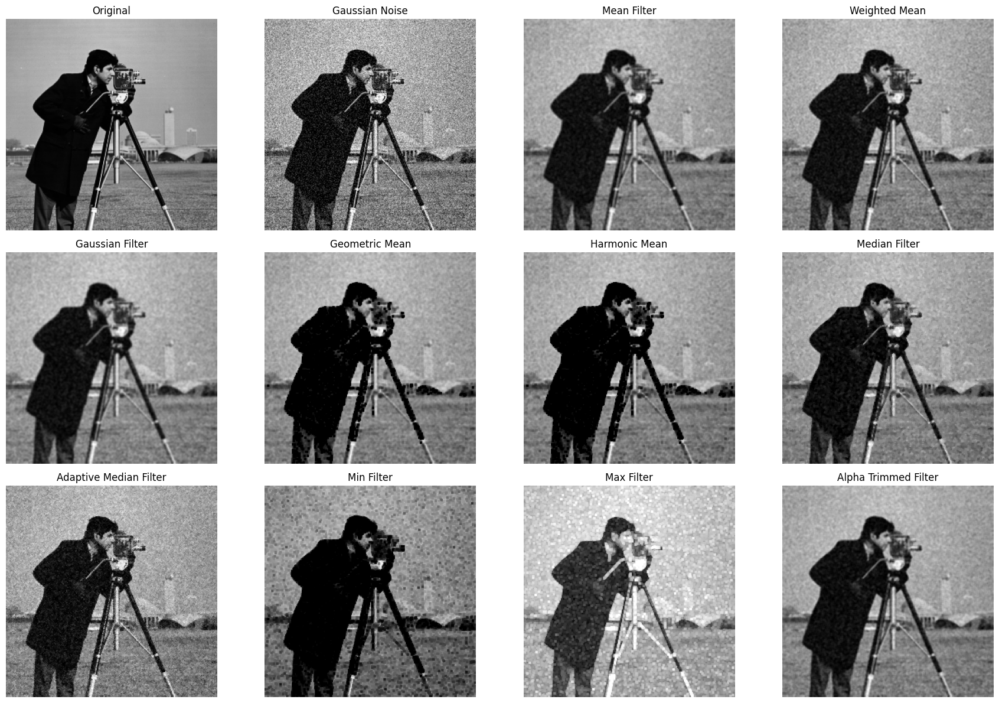

In [6]:

gaussian_results = {
    "Mean Filter": mean_filter(gaussian_noisy),
    "Weighted Mean": weighted_mean_filter(gaussian_noisy),
    "Gaussian Filter": gaussian_filter(gaussian_noisy),
    "Geometric Mean": geomtric_mean_filter(gaussian_noisy),
    "Harmonic Mean": harmonic_mean_filter(gaussian_noisy),
    "Median Filter": median_filter(gaussian_noisy),
    "Adaptive Median Filter": adaptive_median_filter(gaussian_noisy),
    "Min Filter": min_filter(gaussian_noisy),
    "Max Filter": max_filter(gaussian_noisy),
    "Alpha Trimmed Filter": alpha_trimmed_filter(gaussian_noisy)
}

fig, axes = plt.subplots(3,4, figsize=(18,12))

axes = axes.flatten()

axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(gaussian_noisy, cmap='gray')
axes[1].set_title("Gaussian Noise")
axes[1].axis('off')

index = 2

for name, image in gaussian_results.items():

    axes[index].imshow(image, cmap='gray')
    axes[index].set_title(name)
    axes[index].axis('off')

    index += 1

plt.tight_layout()
plt.show()



# Apply Filters on Salt & Pepper Noise


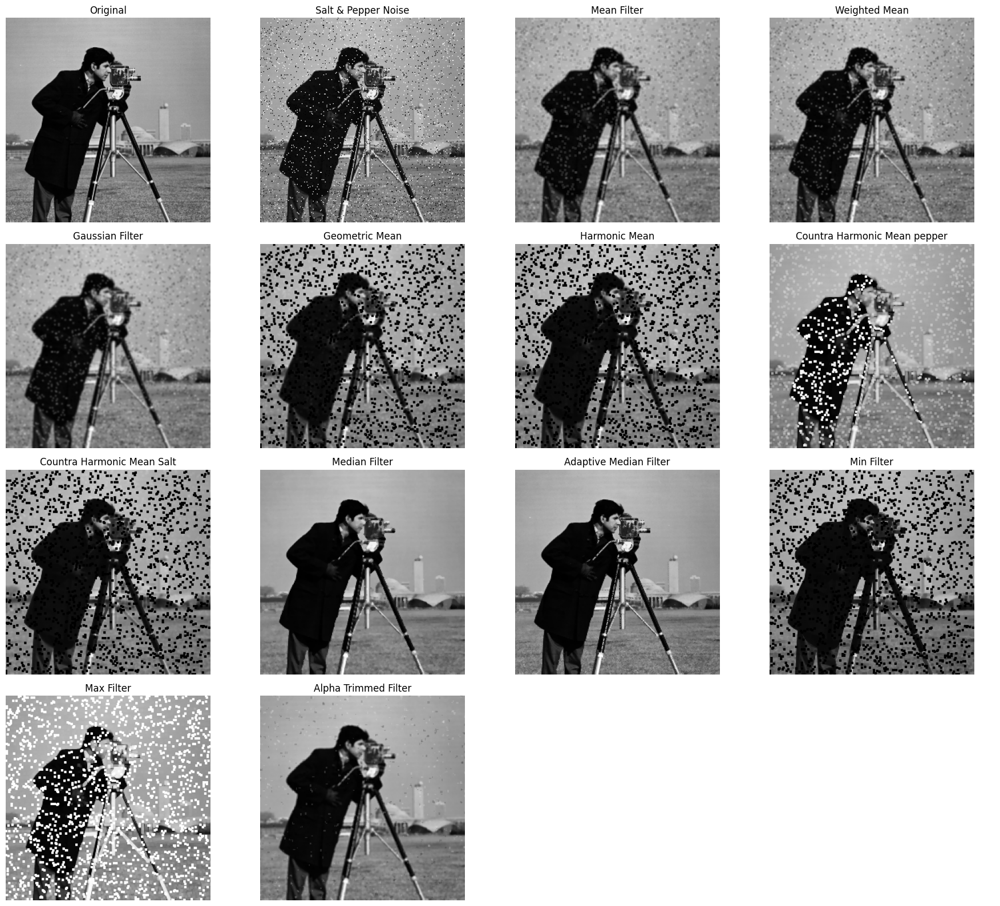

In [14]:

sp_results = {
    "Mean Filter": mean_filter(sp_noisy),
    "Weighted Mean": weighted_mean_filter(sp_noisy),
    "Gaussian Filter": gaussian_filter(sp_noisy),
    "Geometric Mean": geomtric_mean_filter(sp_noisy),
    "Harmonic Mean": harmonic_mean_filter(sp_noisy),
    "Countra Harmonic Mean pepper": countra_harmonic_mean_filter_for_pepper(sp_noisy),
    "Countra Harmonic Mean Salt": countra_harmonic_mean_filter_for_salt(sp_noisy),
    "Median Filter": median_filter(sp_noisy),
    "Adaptive Median Filter": adaptive_median_filter(sp_noisy),
    "Min Filter": min_filter(sp_noisy),
    "Max Filter": max_filter(sp_noisy),
    "Alpha Trimmed Filter": alpha_trimmed_filter(sp_noisy)
}

fig, axes = plt.subplots(4,4, figsize=(18,16))

axes = axes.flatten()

axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(sp_noisy, cmap='gray')
axes[1].set_title("Salt & Pepper Noise")
axes[1].axis('off')

index = 2

for name, image in sp_results.items():

    axes[index].imshow(image, cmap='gray')
    axes[index].set_title(name)
    axes[index].axis('off')

    index += 1

for i in range(index, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()



# Frequency Domain Filters
Implemented manually:
- Ideal Low Pass Filter (ILPF)
- Butterworth Low Pass Filter (BLPF)
- Gaussian Low Pass Filter (GLPF)
- Ideal Band Reject Filter (IBRF)
- Butterworth Band Reject Filter (BBRF)
- Gaussian Band Reject Filter (GBRF)
- Ideal Notch Reject Filter (INRF)
- Butterworth Notch Reject Filter (BNRF)
- Gaussian Notch Reject Filter (GNRF)


In [8]:

def distance_map(rows, cols):

    u = np.arange(rows) - rows // 2
    v = np.arange(cols) - cols // 2

    V, U = np.meshgrid(v, u)

    return np.sqrt(U**2 + V**2)


def apply_frequency_filter(image, H):

    F = np.fft.fft2(image.astype(np.float64))

    F_shifted = np.fft.fftshift(F)

    G_shifted = F_shifted * H

    G = np.fft.ifftshift(G_shifted)

    g = np.fft.ifft2(G).real

    return np.clip(g,0,255).astype(np.uint8)


def ideal_low_pass_filter(image, cutoff=30):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    H = np.zeros((rows, cols))

    H[D <= cutoff] = 1

    return apply_frequency_filter(image, H)


def butterworth_low_pass_filter(image, cutoff=30, order=2):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    D = np.where(D == 0, 1e-10, D)

    H = 1 / (1 + (D / cutoff)**(2 * order))

    return apply_frequency_filter(image, H)


def gaussian_low_pass_filter(image, cutoff=30):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    H = np.exp(-(D**2) / (2 * cutoff**2))

    return apply_frequency_filter(image, H)


def ideal_band_reject_filter(image, cutoff=40, width=15):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    H = np.ones((rows, cols))

    lower = cutoff - (width / 2)
    upper = cutoff + (width / 2)

    H[(D >= lower) & (D <= upper)] = 0

    return apply_frequency_filter(image, H)


def butterworth_band_reject_filter(image, cutoff=40, width=15, order=2):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    D = np.where(D == 0, 1e-10, D)

    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.divide(D * width, D**2 - cutoff**2, out=np.full_like(D, np.inf), where=np.abs(D**2-cutoff**2)>1e-12)
        H = 1 / (1 + ratio**(2 * order))

    return apply_frequency_filter(image, H)


def gaussian_band_reject_filter(image, cutoff=40, width=15):

    rows, cols = image.shape

    D = distance_map(rows, cols)

    D = np.where(D == 0, 1e-10, D)

    # Gaussian band reject: zero near D=cutoff; one far away.
    H = 1 - np.exp(-0.5 * ((D**2 - cutoff**2) / (np.maximum(D, 1e-10) * width))**2)

    return apply_frequency_filter(image, H)


def ideal_notch_reject_filter(image, D0=10, uk=30, vk=30):

    rows, cols = image.shape

    u = np.arange(rows) - rows // 2
    v = np.arange(cols) - cols // 2

    V, U = np.meshgrid(v, u)

    Dk = np.sqrt((U - uk)**2 + (V - vk)**2)
    Dk_neg = np.sqrt((U + uk)**2 + (V + vk)**2)

    H = np.ones((rows, cols))

    H[Dk <= D0] = 0
    H[Dk_neg <= D0] = 0

    return apply_frequency_filter(image, H)


def butterworth_notch_reject_filter(image, D0=10, uk=30, vk=30, order=2):

    rows, cols = image.shape

    u = np.arange(rows) - rows // 2
    v = np.arange(cols) - cols // 2

    V, U = np.meshgrid(v, u)

    Dk = np.sqrt((U - uk)**2 + (V - vk)**2)
    Dk_neg = np.sqrt((U + uk)**2 + (V + vk)**2)

    Dk = np.where(Dk == 0, 1e-10, Dk)
    Dk_neg = np.where(Dk_neg == 0, 1e-10, Dk_neg)

    H = 1 / (
        1 + ((D0**2) / (Dk * Dk_neg))**order
    )

    return apply_frequency_filter(image, H)


def gaussian_notch_reject_filter(image, D0=10, uk=30, vk=30):

    rows, cols = image.shape

    u = np.arange(rows) - rows // 2
    v = np.arange(cols) - cols // 2

    V, U = np.meshgrid(v, u)

    Dk = np.sqrt((U - uk)**2 + (V - vk)**2)
    Dk_neg = np.sqrt((U + uk)**2 + (V + vk)**2)

    H = 1 - np.exp(-0.5 * (Dk * Dk_neg) / (D0**2))

    return apply_frequency_filter(image, H)


**Periodic-noise notch location:** the synthetic sinusoid uses `(freq_x, freq_y) = (25, 25)` in row/column frequency coordinates. Use the corresponding symmetric frequency spikes rather than arbitrary `(30, 30)` offsets.

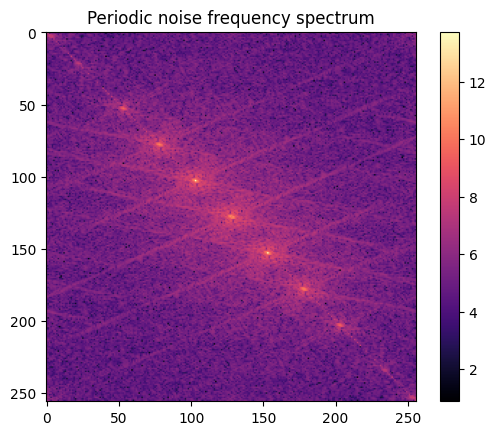

In [9]:
# Diagnostic: identify the two symmetric peaks in the noisy-minus-original spectrum.
residual = periodic_noisy.astype(float) - original.astype(float)
spectrum = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(residual))))
plt.imshow(spectrum, cmap="magma")
plt.title("Periodic noise frequency spectrum")
plt.colorbar()
plt.show()


# Apply Frequency Filters


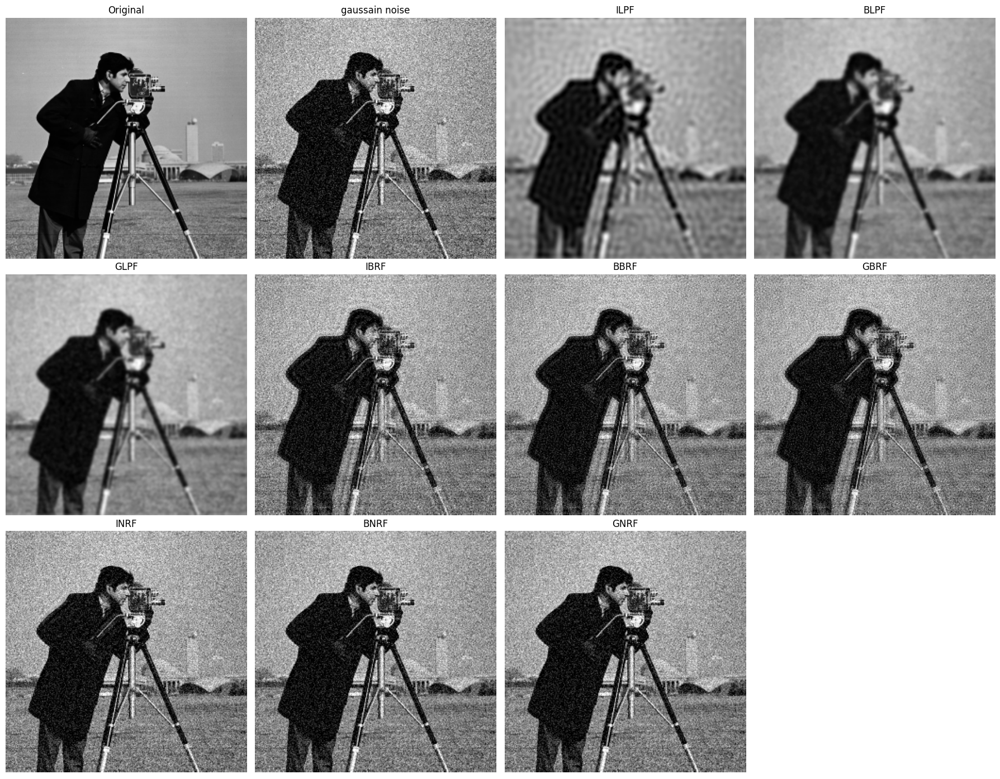

In [10]:

frequency_results = {
    "ILPF": ideal_low_pass_filter(gaussian_noisy),
    "BLPF": butterworth_low_pass_filter(gaussian_noisy),
    "GLPF": gaussian_low_pass_filter(gaussian_noisy),

    "IBRF": ideal_band_reject_filter(gaussian_noisy),
    "BBRF": butterworth_band_reject_filter(gaussian_noisy),
    "GBRF": gaussian_band_reject_filter(gaussian_noisy),

    "INRF": ideal_notch_reject_filter(gaussian_noisy),
    "BNRF": butterworth_notch_reject_filter(gaussian_noisy),
    "GNRF": gaussian_notch_reject_filter(gaussian_noisy)
}

fig, axes = plt.subplots(3,4, figsize=(18,14))

axes = axes.flatten()

axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(gaussian_noisy, cmap='gray')
axes[1].set_title("gaussain noise")
axes[1].axis('off')

index = 2

for name, image in frequency_results.items():

    axes[index].imshow(image, cmap='gray')
    axes[index].set_title(name)
    axes[index].axis('off')

    index += 1

for i in range(index, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


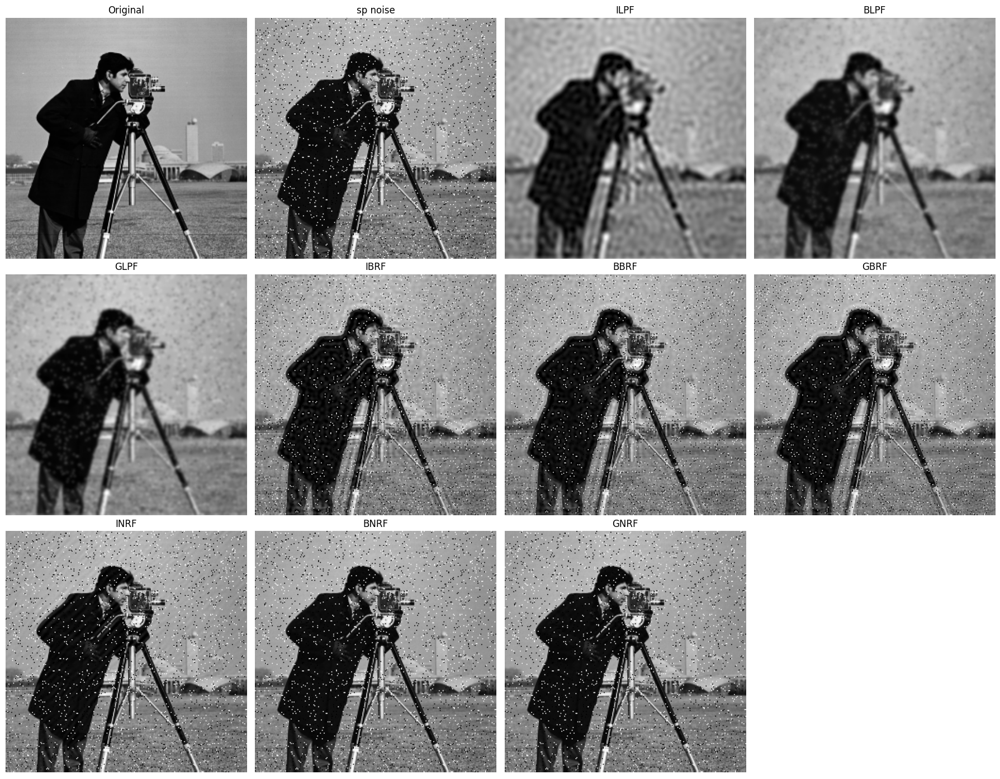

In [11]:

frequency_results = {
    "ILPF": ideal_low_pass_filter(sp_noisy),
    "BLPF": butterworth_low_pass_filter(sp_noisy),
    "GLPF": gaussian_low_pass_filter(sp_noisy),

    "IBRF": ideal_band_reject_filter(sp_noisy),
    "BBRF": butterworth_band_reject_filter(sp_noisy),
    "GBRF": gaussian_band_reject_filter(sp_noisy),

    "INRF": ideal_notch_reject_filter(sp_noisy),
    "BNRF": butterworth_notch_reject_filter(sp_noisy),
    "GNRF": gaussian_notch_reject_filter(sp_noisy)
}

fig, axes = plt.subplots(3,4, figsize=(18,14))

axes = axes.flatten()

axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(sp_noisy, cmap='gray')
axes[1].set_title("sp noise")
axes[1].axis('off')

index = 2

for name, image in frequency_results.items():

    axes[index].imshow(image, cmap='gray')
    axes[index].set_title(name)
    axes[index].axis('off')

    index += 1

for i in range(index, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


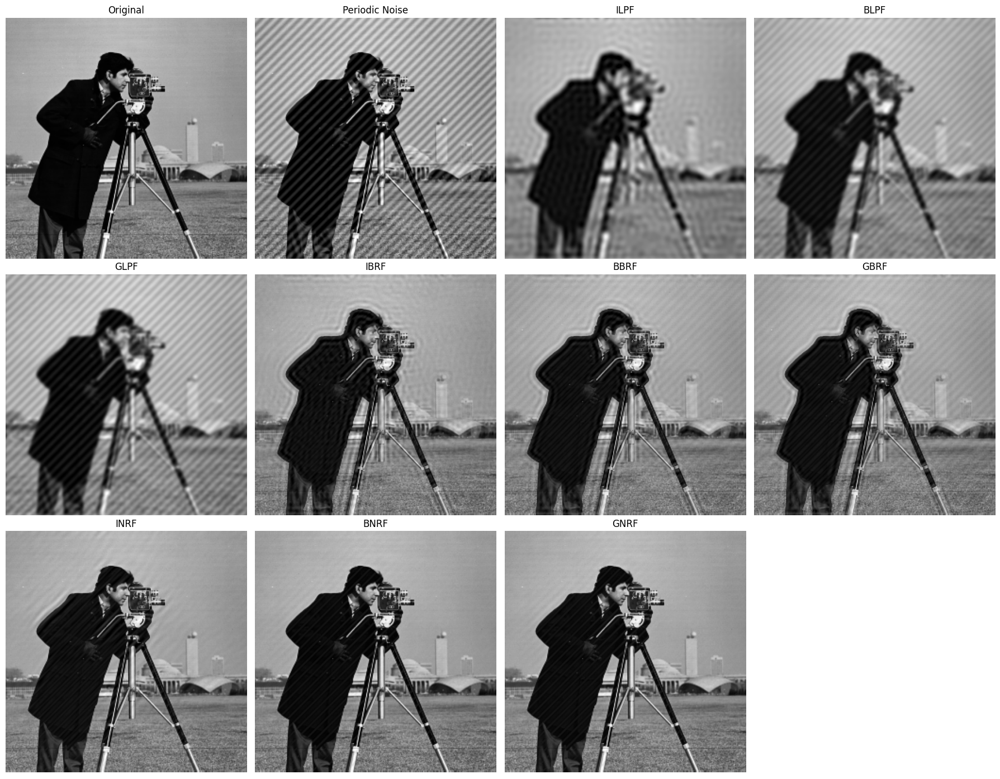

In [12]:
periodic_frequency_results = {
    "ILPF": ideal_low_pass_filter(periodic_noisy),
    "BLPF": butterworth_low_pass_filter(periodic_noisy),
    "GLPF": gaussian_low_pass_filter(periodic_noisy),

    "IBRF": ideal_band_reject_filter(periodic_noisy),
    "BBRF": butterworth_band_reject_filter(periodic_noisy),
    "GBRF": gaussian_band_reject_filter(periodic_noisy),

    "INRF": ideal_notch_reject_filter(periodic_noisy, uk=25, vk=25),
    "BNRF": butterworth_notch_reject_filter(periodic_noisy, uk=25, vk=25),
    "GNRF": gaussian_notch_reject_filter(periodic_noisy, uk=25, vk=25)
}

fig, axes = plt.subplots(3,4, figsize=(18,14))

axes = axes.flatten()

axes[0].imshow(original, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(periodic_noisy, cmap='gray')
axes[1].set_title("Periodic Noise")
axes[1].axis('off')

index = 2

for name, image in periodic_frequency_results.items():

    axes[index].imshow(image, cmap='gray')
    axes[index].set_title(name)
    axes[index].axis('off')

    index += 1

for i in range(index, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


# Conclusion

- Mean and Gaussian filters work well for Gaussian noise.
- Median filter performs best for Salt & Pepper noise.
- Frequency domain filters smooth high-frequency noise.
- Large kernels increase smoothing but may blur edges.


## Quantitative evaluation
Compare each restored image against the same clean reference. Higher PSNR/SSIM and lower MSE indicate better fidelity. These scores are not available until the notebook is executed.

In [13]:
from skimage.metrics import structural_similarity as structural_similarity_index

def evaluate(reference, estimate):
    ref = reference.astype(np.float64)
    est = estimate.astype(np.float64)
    mse = float(np.mean((ref - est)**2))
    psnr = float("inf") if mse == 0 else float(10*np.log10(255**2/mse))
    ssim = float(structural_similarity_index(reference, estimate, data_range=255))
    return {"MSE": mse, "PSNR (dB)": psnr, "SSIM": ssim}

def show_scores(noisy, results):
    import pandas as pd
    scores = {"Noisy input": evaluate(original, noisy)}
    scores.update({name: evaluate(original, img) for name, img in results.items()})
    return pd.DataFrame.from_dict(scores, orient="index").sort_values("PSNR (dB)", ascending=False)

print("Spatial filters on Gaussian noise")
display(show_scores(gaussian_noisy, gaussian_results))
print("Spatial filters on Salt & Pepper noise")
display(show_scores(sp_noisy, sp_results))
print("Frequency filters on periodic noise")
display(show_scores(periodic_noisy, periodic_frequency_results))

Spatial filters on Gaussian noise


,MSE,PSNR (dB),SSIM
Weighted Mean,189.460480,25.355617,0.610478
Gaussian Filter,211.762665,24.872310,0.661762
Alpha Trimmed Filter,220.091110,24.704779,0.602279
Mean Filter,234.179871,24.435308,0.605640
Median Filter,236.944748,24.384333,0.545926
Adaptive Median Filter,336.032150,22.866995,0.432250
Geometric Mean,501.150009,21.131126,0.483830
Noisy input,572.193207,20.555377,0.363197
Harmonic Mean,653.816040,19.976248,0.451514
Min Filter,2234.523804,14.638954,0.269338


Spatial filters on Salt & Pepper noise


,MSE,PSNR (dB),SSIM
Adaptive Median Filter,54.018295,30.805395,0.946585
Median Filter,135.464386,26.812552,0.873952
Alpha Trimmed Filter,174.379715,25.715844,0.781865
Gaussian Filter,256.375183,24.042044,0.597768
Weighted Mean,257.594345,24.021440,0.556583
Mean Filter,289.529938,23.513869,0.545044
Noisy input,996.998169,18.143860,0.394210
Countra Harmonic Mean pepper,2585.374100,14.005570,0.437722
Geometric Mean,3376.079208,12.846677,0.305527
Harmonic Mean,3898.145081,12.222224,0.292460


Frequency filters on periodic noise


,MSE,PSNR (dB),SSIM
GNRF,9.735321,38.247301,0.956314
BNRF,11.127533,37.666815,0.955163
INRF,25.839569,34.007951,0.928760
BBRF,110.808121,27.685088,0.803043
IBRF,117.665283,27.424320,0.807741
GBRF,122.346863,27.254875,0.781352
BLPF,346.300705,22.736270,0.541538
GLPF,357.733322,22.595210,0.456888
ILPF,362.752884,22.534695,0.651667
Noisy input,416.511871,21.934530,0.400243


## Interpretation and limitations
The original report compares outputs visually. This revision adds quantitative comparisons; actual rankings depend on the image, noise realization, filter parameters, and boundary handling. The project is collaborative and the original team credits are preserved.